In [1]:
# ============================================================
# K-NEAREST NEIGHBORS (KNN) CLASSIFICATION
# IRIS DATASET
# ============================================================

# ------------------------------------------------------------
# STEP 1: IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)




In [3]:
# ------------------------------------------------------------
# STEP 2: LOAD THE DATASET
# ------------------------------------------------------------

# Path of your uploaded dataset
file_path = r"C:\Users\tbhog\OneDrive\Desktop\classes projects\ml\iris\Iris.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print()




Dataset loaded successfully!



In [4]:
# ------------------------------------------------------------
# STEP 3: DISPLAY BASIC INFORMATION
# ------------------------------------------------------------

print("First 5 rows of the dataset:")
print(df.head())

print("\nLast 5 rows of the dataset:")
print(df.tail())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df["Species"].value_counts())


# ------------------------------------------------------------
# STEP 4: DATA CLEANING
# ------------------------------------------------------------

# Check duplicate rows
print("\nNumber of duplicate rows:",
      df.duplicated().sum())

# Remove duplicate rows if present
df = df.drop_duplicates()

# Check missing values
if df.isnull().sum().sum() > 0:
    print("\nMissing values found. Removing rows...")
    df = df.dropna()
else:
    print("\nNo missing values found.")




First 5 rows of the dataset:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Last 5 rows of the dataset:
      Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  \
145  146            6.7           3.0            5.2           2.3   
146  147            6.3           2.5            5.0           1.9   
147  148            6.5           3.0            5.2           2.0   
148  149            6.2           3.4            5.4           2.3   
149  150            5.9           3.0            5.1           1.8   

            Species  
145  Iris-virginica  
146  Iris-virgi

In [5]:
# ------------------------------------------------------------
# STEP 5: DEFINE FEATURES AND TARGET
# ------------------------------------------------------------

# We don't need the Id column for prediction.
# The four measurements will be used as input features.

X = df[
    [
        "SepalLengthCm",
        "SepalWidthCm",
        "PetalLengthCm",
        "PetalWidthCm"
    ]
]

# Target variable
y = df["Species"]

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())





Features:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2

Target:
0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: Species, dtype: object


In [6]:
# ------------------------------------------------------------
# STEP 6: SPLIT DATA INTO TRAINING AND TESTING
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])





Training samples: 120
Testing samples: 30


In [7]:
# ------------------------------------------------------------
# STEP 7: FEATURE SCALING
# ------------------------------------------------------------

# KNN uses distance calculations.
# Therefore, feature scaling is very important.

scaler = StandardScaler()

# Fit scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling completed.")

print("\nScaled Training Data:")
print(X_train_scaled[:5])




Feature scaling completed.

Scaled Training Data:
[[-1.72156775 -0.32483982 -1.34703555 -1.32016847]
 [-1.12449223 -1.22612948  0.41429037  0.65186742]
 [ 1.14439475 -0.55016223  0.58474127  0.25746024]
 [-1.12449223  0.12580502 -1.29021859 -1.45163753]
 [-0.40800161 -1.22612948  0.13020555  0.12599118]]


In [8]:

# ------------------------------------------------------------
# STEP 8: CREATE KNN MODEL
# ------------------------------------------------------------

# Number of neighbors
k = 5

knn = KNeighborsClassifier(
    n_neighbors=k,
    weights="uniform",
    metric="euclidean"
)

print("\nKNN Model:")
print(knn)


# ------------------------------------------------------------
# STEP 9: TRAIN THE KNN MODEL
# ------------------------------------------------------------

knn.fit(X_train_scaled, y_train)

print("\nKNN model trained successfully!")


# ------------------------------------------------------------
# STEP 10: MAKE PREDICTIONS
# ------------------------------------------------------------

y_pred = knn.predict(X_test_scaled)

print("\nPredicted values:")
print(y_pred)

print("\nActual values:")
print(y_test.values)


# ------------------------------------------------------------
# STEP 11: CALCULATE ACCURACY
# ------------------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\n========================================")
print("MODEL ACCURACY")
print("========================================")
print(f"Accuracy: {accuracy * 100:.2f}%")


# ------------------------------------------------------------
# STEP 12: PRECISION, RECALL AND F1-SCORE
# ------------------------------------------------------------

precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("\n========================================")
print("MODEL PERFORMANCE")
print("========================================")
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1-Score  : {f1 * 100:.2f}%")


# ------------------------------------------------------------
# STEP 13: CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n========================================")
print("CLASSIFICATION REPORT")
print("========================================")

print(
    classification_report(
        y_test,
        y_pred
    )
)





KNN Model:
KNeighborsClassifier(metric='euclidean')

KNN model trained successfully!

Predicted values:
['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-setosa'
 'Iris-virginica' 'Iris-setosa']

Actual values:
['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica'
 'Iris-setosa' 'Iris-virginica' 'Iris-versicolo


CONFUSION MATRIX
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


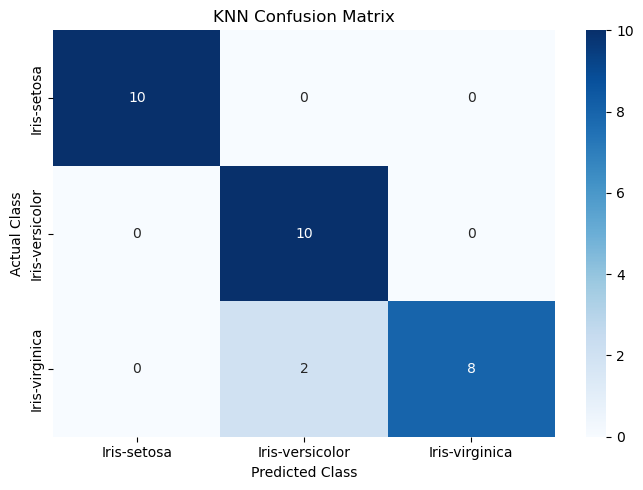

In [9]:
# ------------------------------------------------------------
# STEP 14: CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

print("\n========================================")
print("CONFUSION MATRIX")
print("========================================")

print(cm)


# ------------------------------------------------------------
# STEP 15: VISUALIZE CONFUSION MATRIX
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=knn.classes_,
    yticklabels=knn.classes_
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()





BEST K VALUE
Best K: 1
Best Accuracy: 96.67%


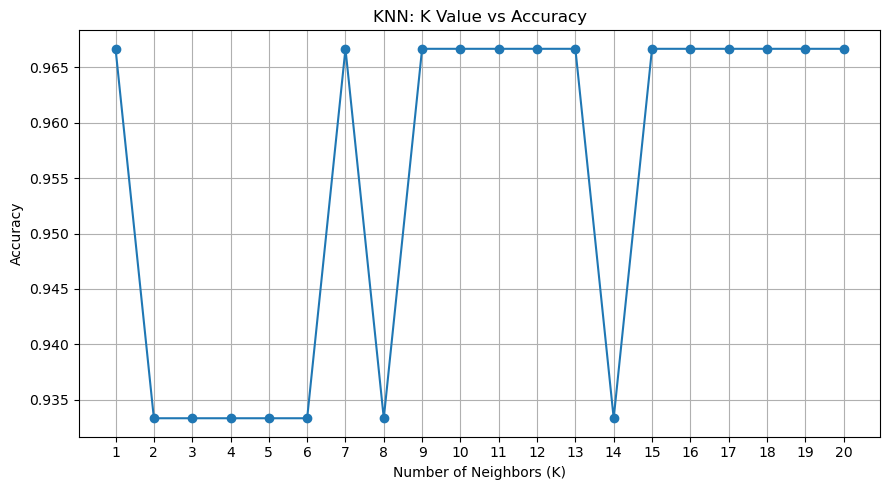


Final KNN model trained using K = 1

FINAL MODEL RESULTS
Final Accuracy: 96.67%

NEW FLOWER PREDICTION
Input measurements:
[[5.1 3.5 1.4 0.2]]

Predicted Species:
Iris-setosa

Prediction probabilities:
Iris-setosa: 100.00%
Iris-versicolor: 0.00%
Iris-virginica: 0.00%

ACTUAL VS PREDICTED
             Actual        Predicted
0       Iris-setosa      Iris-setosa
1    Iris-virginica   Iris-virginica
2   Iris-versicolor  Iris-versicolor
3   Iris-versicolor  Iris-versicolor
4       Iris-setosa      Iris-setosa
5   Iris-versicolor  Iris-versicolor
6       Iris-setosa      Iris-setosa
7       Iris-setosa      Iris-setosa
8    Iris-virginica   Iris-virginica
9   Iris-versicolor  Iris-versicolor
10   Iris-virginica   Iris-virginica
11   Iris-virginica   Iris-virginica
12   Iris-virginica   Iris-virginica
13  Iris-versicolor  Iris-versicolor
14      Iris-setosa      Iris-setosa
15      Iris-setosa      Iris-setosa
16      Iris-setosa      Iris-setosa
17  Iris-versicolor  Iris-versicolor
18  Iri

D:\anaconda\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


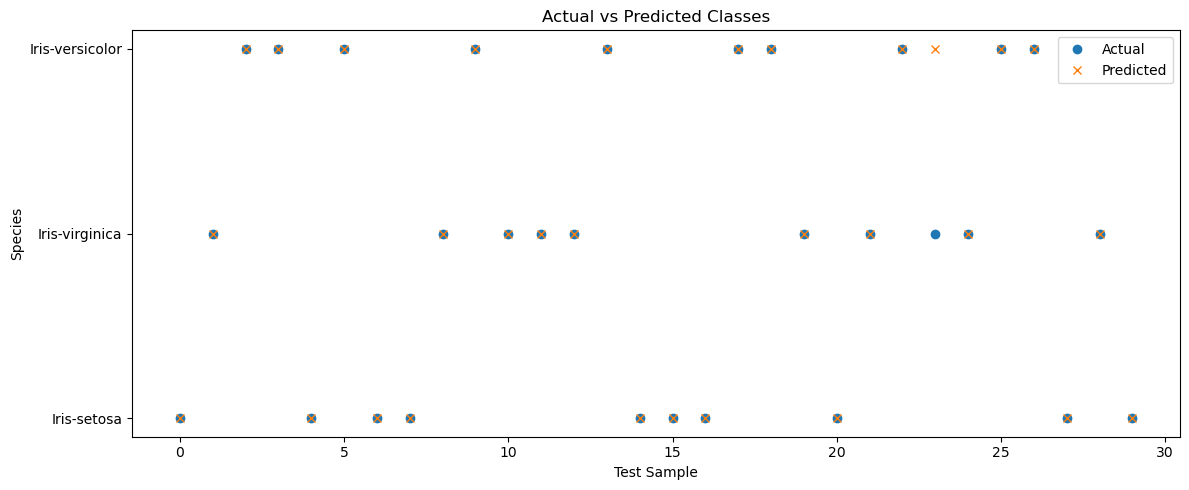


KNN CLASSIFICATION COMPLETED


In [10]:
# ------------------------------------------------------------
# STEP 16: FIND THE BEST VALUE OF K
# ------------------------------------------------------------

k_values = range(1, 21)

accuracy_values = []

for k in k_values:

    model = KNeighborsClassifier(
        n_neighbors=k,
        metric="euclidean"
    )

    model.fit(X_train_scaled, y_train)

    prediction = model.predict(X_test_scaled)

    acc = accuracy_score(
        y_test,
        prediction
    )

    accuracy_values.append(acc)


# Find best K
best_k = k_values[
    np.argmax(accuracy_values)
]

best_accuracy = max(accuracy_values)

print("\n========================================")
print("BEST K VALUE")
print("========================================")

print("Best K:", best_k)
print(
    f"Best Accuracy: {best_accuracy * 100:.2f}%"
)


# ------------------------------------------------------------
# STEP 17: PLOT K VS ACCURACY
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    k_values,
    accuracy_values,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")

plt.title("KNN: K Value vs Accuracy")

plt.xticks(list(k_values))
plt.grid(True)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# STEP 18: TRAIN FINAL MODEL USING BEST K
# ------------------------------------------------------------

final_knn = KNeighborsClassifier(
    n_neighbors=best_k,
    metric="euclidean"
)

final_knn.fit(
    X_train_scaled,
    y_train
)

print("\nFinal KNN model trained using K =", best_k)


# ------------------------------------------------------------
# STEP 19: TEST FINAL MODEL
# ------------------------------------------------------------

final_prediction = final_knn.predict(
    X_test_scaled
)

final_accuracy = accuracy_score(
    y_test,
    final_prediction
)

print("\n========================================")
print("FINAL MODEL RESULTS")
print("========================================")

print(
    f"Final Accuracy: {final_accuracy * 100:.2f}%"
)


# ------------------------------------------------------------
# STEP 20: PREDICT A NEW IRIS FLOWER
# ------------------------------------------------------------

# Example measurements:
#
# Sepal Length = 5.1 cm
# Sepal Width  = 3.5 cm
# Petal Length = 1.4 cm
# Petal Width  = 0.2 cm

new_flower = np.array([
    [5.1, 3.5, 1.4, 0.2]
])

# Scale the new input using the previously trained scaler
new_flower_scaled = scaler.transform(
    new_flower
)

# Prediction
prediction = final_knn.predict(
    new_flower_scaled
)

print("\n========================================")
print("NEW FLOWER PREDICTION")
print("========================================")

print("Input measurements:")
print(new_flower)

print("\nPredicted Species:")
print(prediction[0])


# ------------------------------------------------------------
# STEP 21: PREDICTION PROBABILITY
# ------------------------------------------------------------

probabilities = final_knn.predict_proba(
    new_flower_scaled
)

print("\nPrediction probabilities:")

for species, probability in zip(
    final_knn.classes_,
    probabilities[0]
):
    print(
        f"{species}: {probability * 100:.2f}%"
    )


# ------------------------------------------------------------
# STEP 22: COMPARE ACTUAL VS PREDICTED
# ------------------------------------------------------------

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": final_prediction
})

print("\n========================================")
print("ACTUAL VS PREDICTED")
print("========================================")

print(results)


# ------------------------------------------------------------
# STEP 23: VISUALIZE ACTUAL VS PREDICTED
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    range(len(y_test)),
    y_test.values,
    "o",
    label="Actual"
)

plt.plot(
    range(len(final_prediction)),
    final_prediction,
    "x",
    label="Predicted"
)

plt.xlabel("Test Sample")
plt.ylabel("Species")

plt.title("Actual vs Predicted Classes")

plt.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# END
# ------------------------------------------------------------

print("\n========================================")
print("KNN CLASSIFICATION COMPLETED")
print("========================================")